# 1. Exploración y preparación del dataset PVEL-AD

Este cuaderno prepara el conjunto de datos común para los modelos de referencia y la variante propuesta.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from photovoltaic_xai import CLASS_NAMES, PROTOCOL_ID, SPLIT_SEED
from photovoltaic_xai.balance import build_balance_plan
from photovoltaic_xai.data_figures import show_cooccurrence, show_defect_examples
from photovoltaic_xai.dataset import compute_normalization
from photovoltaic_xai.notebook_support import project_root
from photovoltaic_xai.preparation import (
    build_splits,
    deduplicate_sources,
    group_visual_candidates,
    save_preparation,
    select_records,
)
from photovoltaic_xai.pvel_ad import DEFAULT_DATASET_DIR, read_sources

PROJECT_ROOT = project_root()
# Change this if dataset is located elsewhere
DATASET_DIR = DEFAULT_DATASET_DIR
IMAGE_SIZE = 512
MIN_SUPPORT = 500

## Inventario y duplicados

Cambia `DATASET_DIR` si guardaste PVEL-AD en otra carpeta. Por defecto apunta a `data/raw/pvel_ad/EL2021`. Se conserva una imagen por SHA-256. Las imágenes parecidas se agrupan antes de aplicar los filtros, para que queden en la misma partición.

In [2]:
sources = read_sources(PROJECT_ROOT, dataset_dir=DATASET_DIR)
inventory = deduplicate_sources(sources)
inventory = group_visual_candidates(inventory)
print(f"{len(sources)} archivos de origen, {len(inventory)} imágenes únicas.")

35003 archivos de origen, 34047 imágenes únicas.


## Selección de los seis defectos

Se excluyen las imágenes con alguna categoría ajena al estudio o con etiquetas contradictorias entre copias. Si solo discrepan las cajas, la imagen se conserva para clasificación. Las sanas llevan seis ceros.

In [3]:
selected_records, selection = select_records(inventory)
assert min(selection["support"].values()) > MIN_SUPPORT, "Insufficient original class support"
print(
    f"{len(selected_records)} imágenes seleccionadas, {len(selection['excluded_ids'])} excluidas."
)

33659 imágenes seleccionadas, 388 excluidas.


## Particiones

Los grupos se reparten entre entrenamiento, validación y prueba con proporciones objetivo de 70 %, 15 % y 15 %. La tabla muestra cuántas imágenes contienen cada defecto en cada partición. Una imagen puede contar en varias filas.

In [4]:
records = build_splits(selected_records)
splits = {
    name: [record for record in records if record["split"] == name]
    for name in ("train", "val", "test")
}
split_support = pd.DataFrame(
    {
        name: np.sum([record["labels"] for record in images], axis=0)
        for name, images in splits.items()
    },
    index=CLASS_NAMES,
)
assert (split_support > 0).all().all(), "Each split needs positives of all six defects"
split_support.loc["Total de imágenes"] = {name: len(images) for name, images in splits.items()}
display(split_support)

,train,val,test
crack,2188,463,471
finger,8924,1904,1920
black_core,3211,686,685
thick_line,1378,296,296
short_circuit,920,197,572
horizontal_dislocation,555,119,119
Total de imágenes,23267,5000,5392


## Normalización

Se ajustan las imágenes a 512 × 512 manteniendo su proporción y rellenando con negro. La media y la desviación se calculan sobre las imágenes originales de entrenamiento, incluido el relleno.

In [5]:
normalization = compute_normalization(splits["train"], PROJECT_ROOT, image_size=IMAGE_SIZE)
pd.Series(normalization)

mean          [0.422341719993547, 0.422341719993547, 0.42234...
std           [0.27575915341335133, 0.27575915341335133, 0.2...
image_size                                                  512
num_images                                                23267
dtype: object

## Balance del entrenamiento

Para balancear el entrenamiento, se construye un plan que mantiene juntas las etiquetas de cada imagen y limita cada original a tres apariciones por época. Esto se hace para evitar que ciertas imágenes dominen el entrenamiento y asegurar una distribución más equitativa de las clases.

In [6]:
train = splits["train"]
plan = build_balance_plan(
    [image["labels"] for image in train], ids=[image["id"] for image in train]
)
original_support, sampled_support = plan.support_counts()
display(
    pd.DataFrame(
        {
            "Originales": original_support,
            "Presentaciones por época": sampled_support,
        },
        index=CLASS_NAMES,
    )
)

,Originales,Presentaciones por época
crack,2188,1605
finger,8924,1961
black_core,3211,1882
thick_line,1378,1605
short_circuit,920,1605
horizontal_dislocation,555,1605


## Guardado

Por último, generamos un JSON con las particiones, la normalización y el plan de muestreo. Los siguientes cuadernos cargan este JSON para usar la misma preparación del experimento.

In [7]:
payload = {
    "protocol_id": PROTOCOL_ID,
    "class_names": list(CLASS_NAMES),
    "seed": SPLIT_SEED,
    "records": records,
    "normalization": normalization,
    "balance": plan.to_dict(),
    "selection": selection,
}
prepared_path = save_preparation(payload, PROJECT_ROOT)
print(prepared_path.relative_to(PROJECT_ROOT), payload["data_fingerprint"], sep="\n")

data/prepared/pvel6-eda-v1.json
2f14794ccc41d8c422b984419118468c9c15db85194a658389de2465e4b99903


## Figuras de la memoria

Una vez hemos preparado los datos y el plan, utilizamos lo que hemos obtenido para extraer gráficas útiles para la memoria.

### Frecuencia y coocurrencia de defectos

En la primera figura vemos la cantidad de imágenes que contienen cada defecto. En la segunda tenemos la matriz de coocurrencia de defectos.
La diagonal de la matriz cuenta las imágenes que contienen cada defecto. El resto de las celdas cuenta las imágenes que contienen ambos.

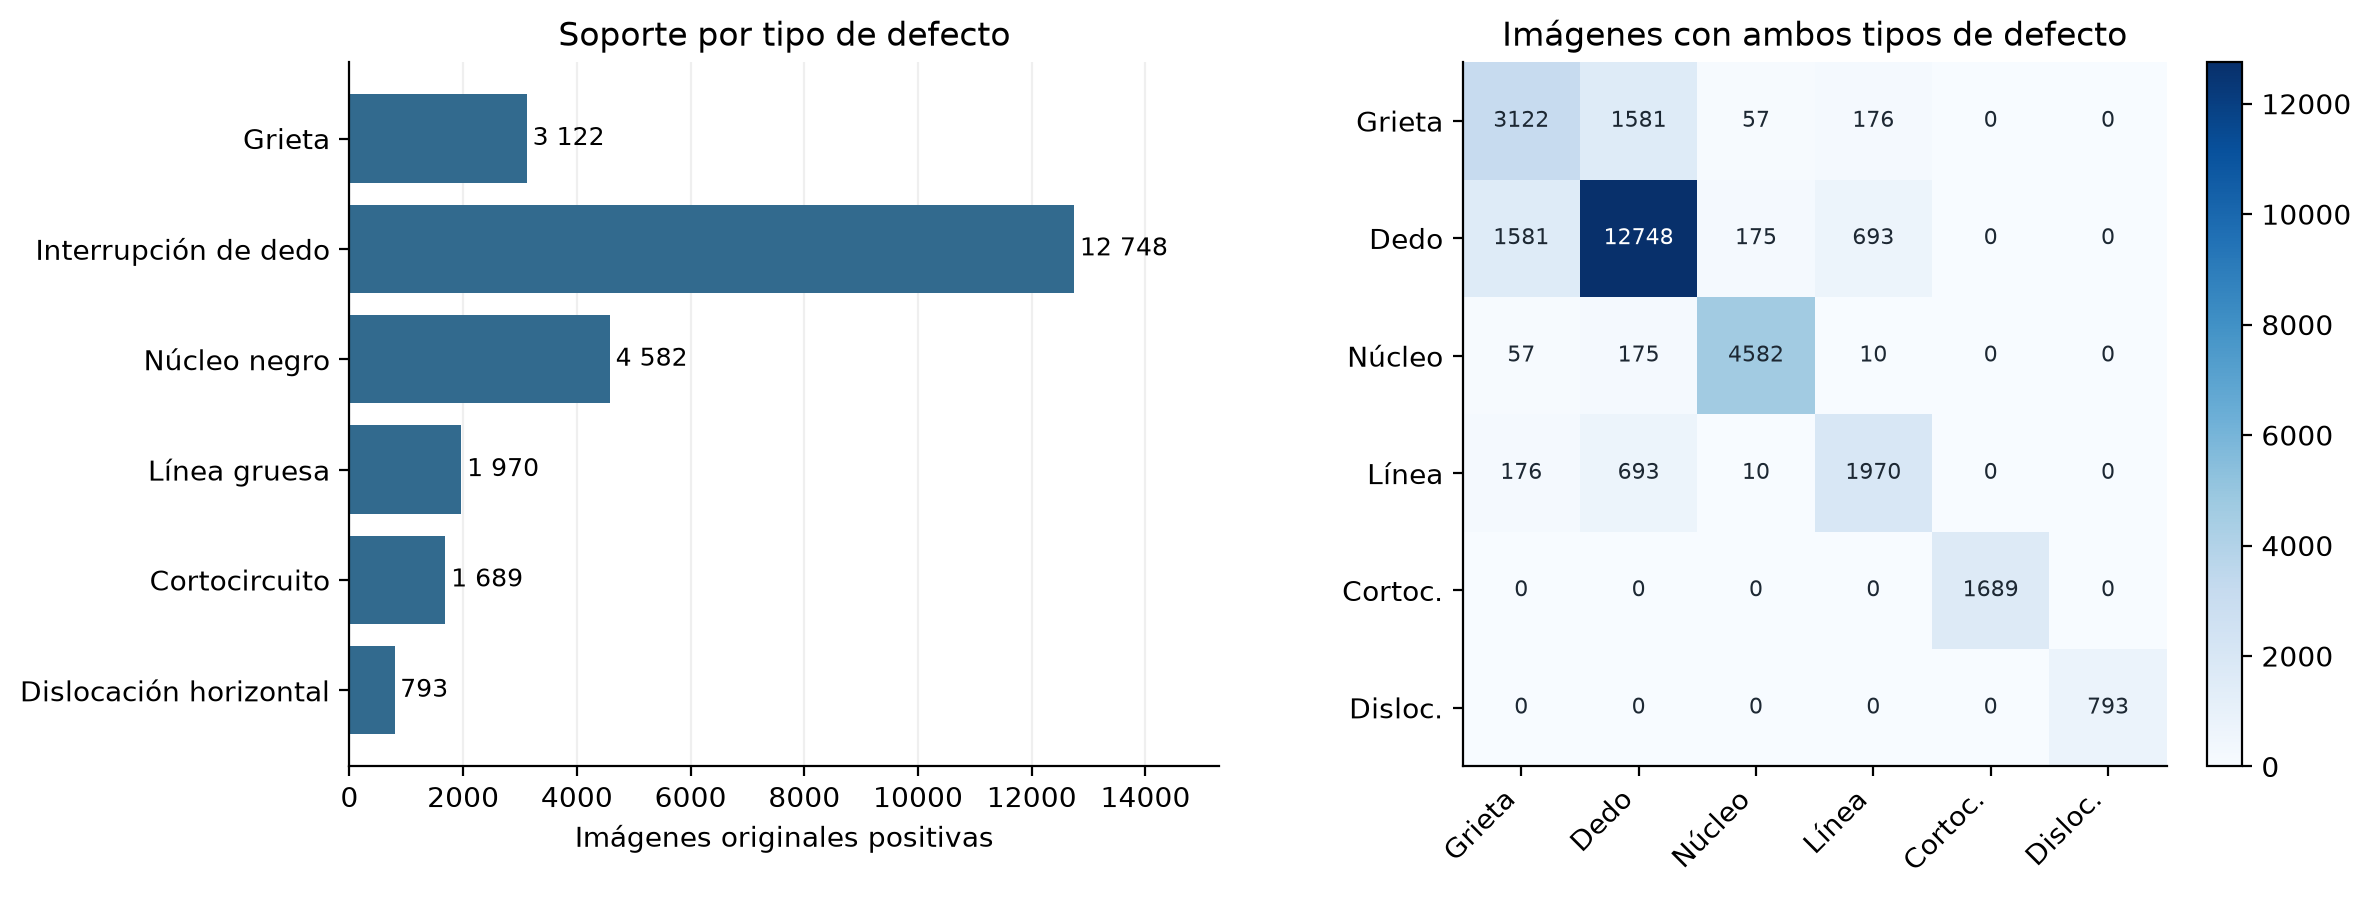

In [8]:
show_cooccurrence(records)

### Ejemplos de los seis defectos

Cada ejemplo de entrenamiento muestra la imagen y un detalle centrado en la caja más grande. El detalle de la dislocación horizontal cubre solo parte de la caja.

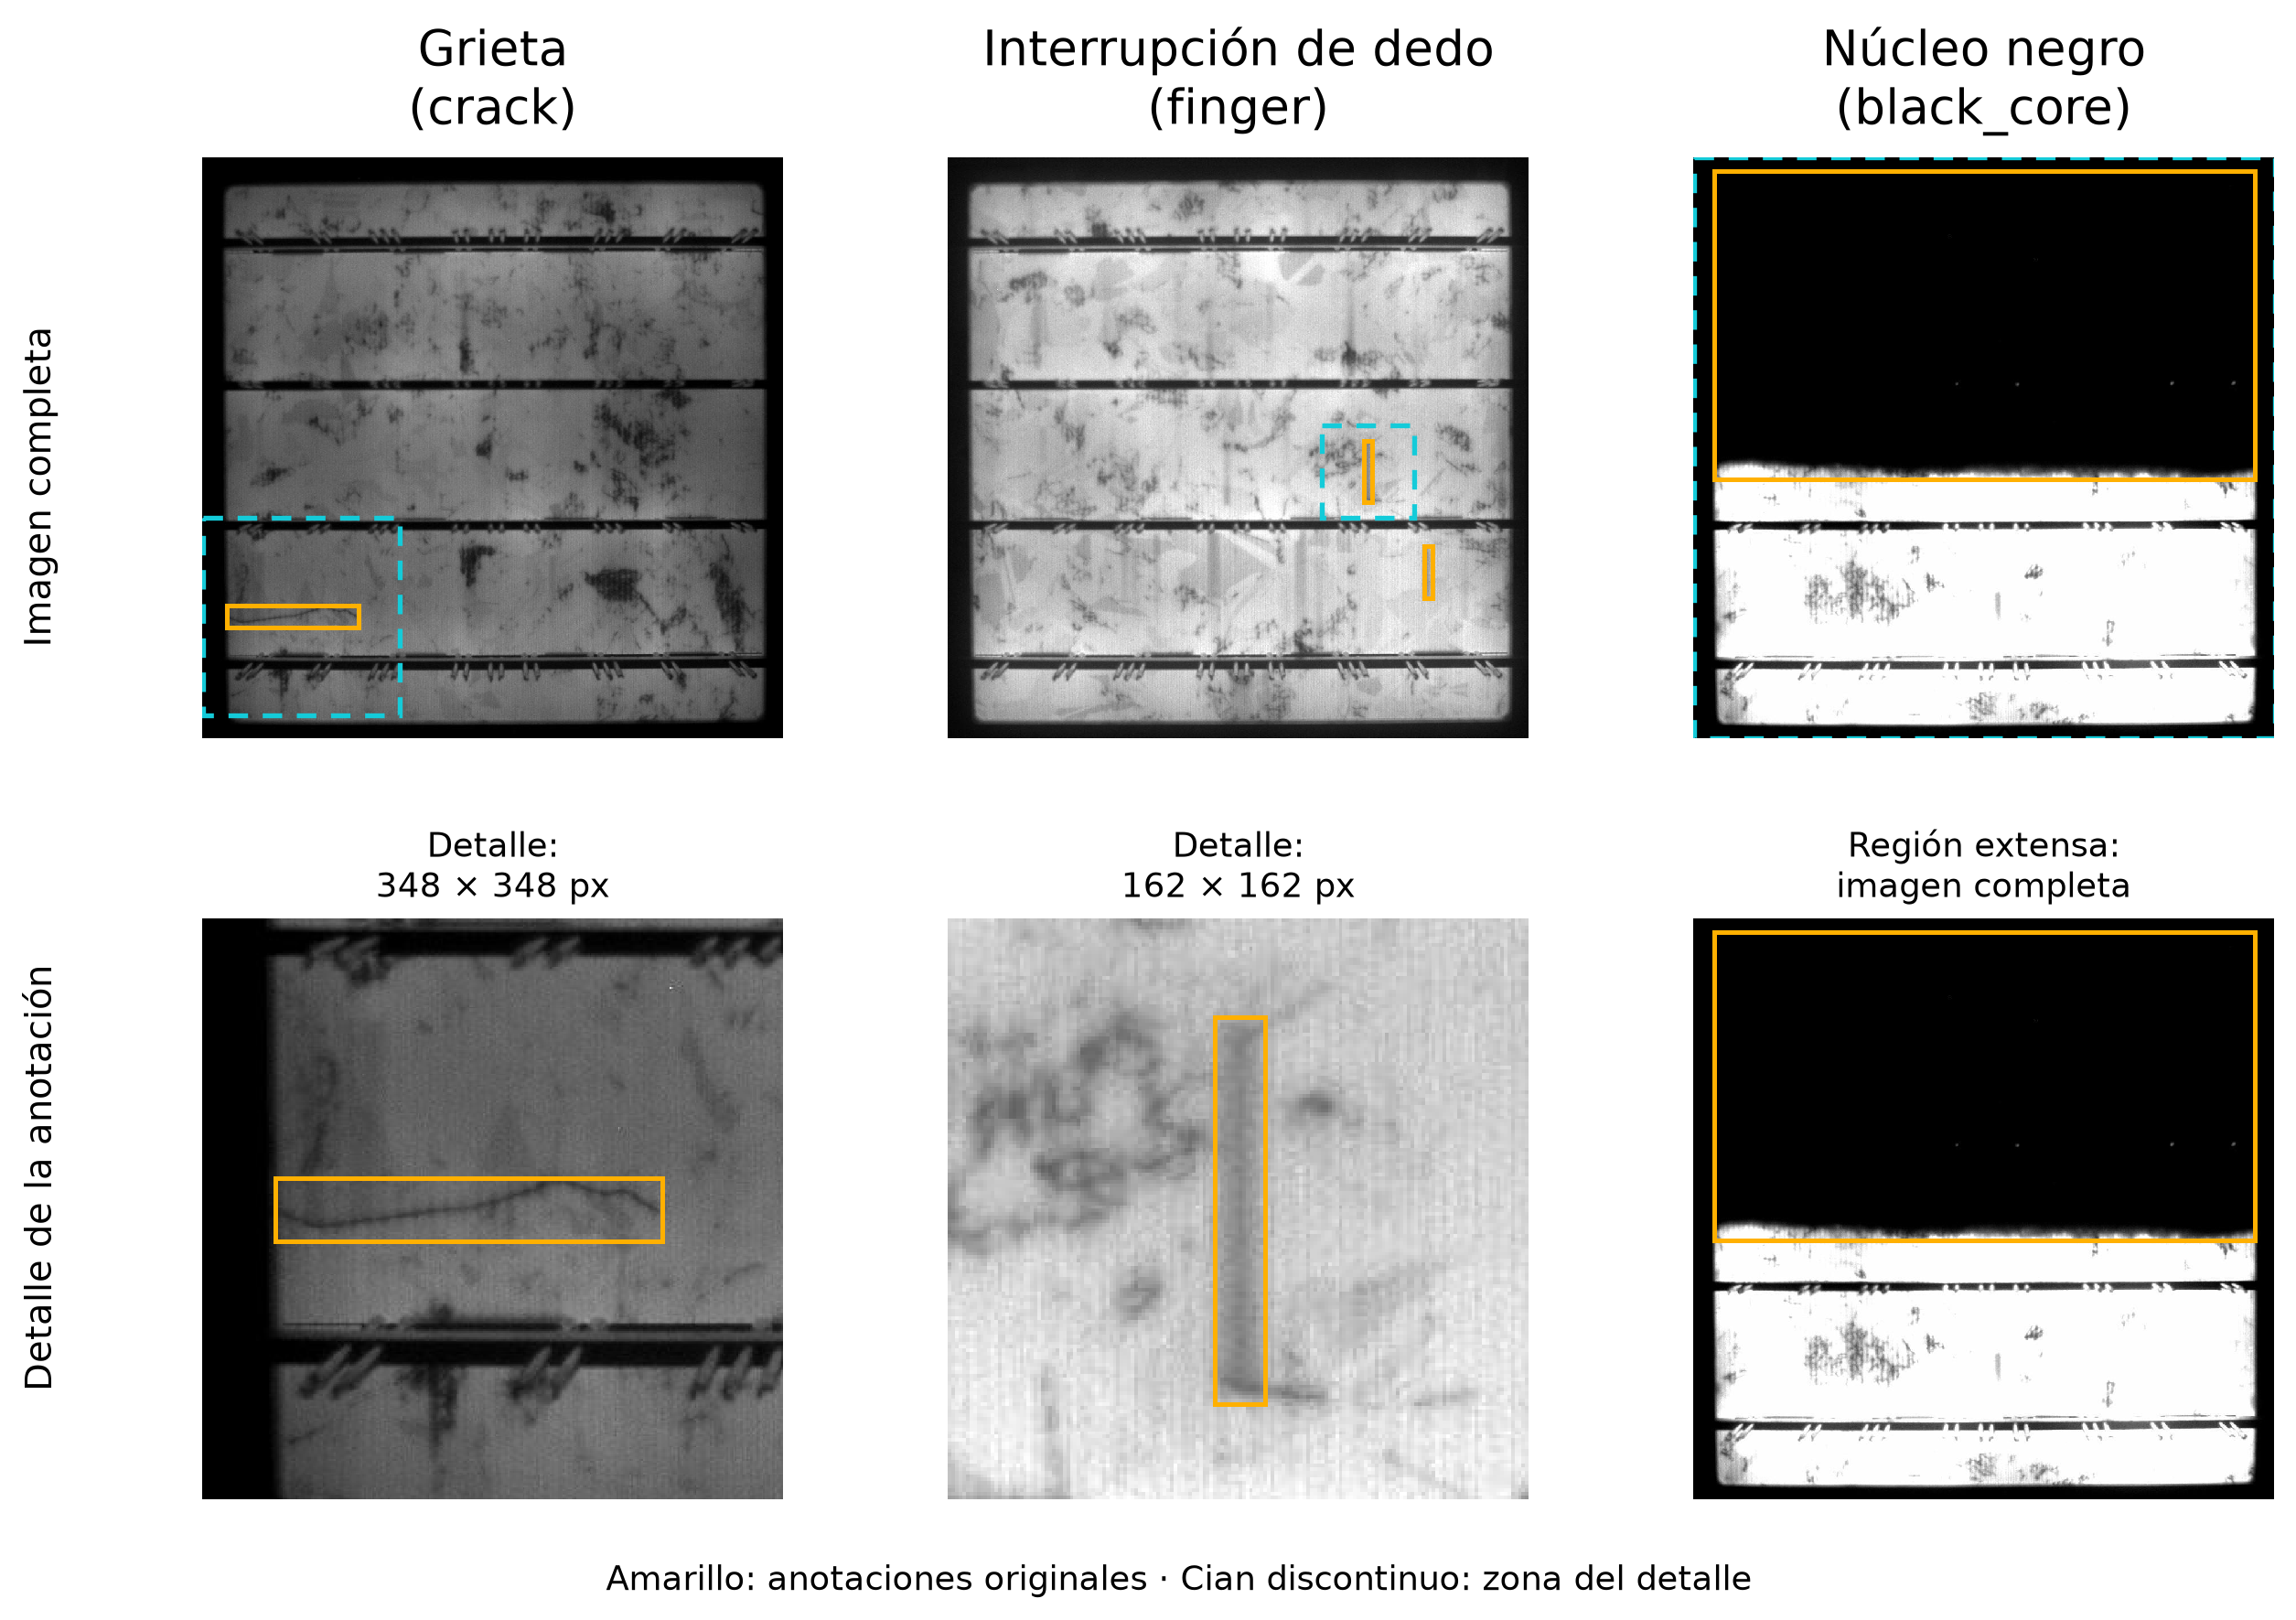

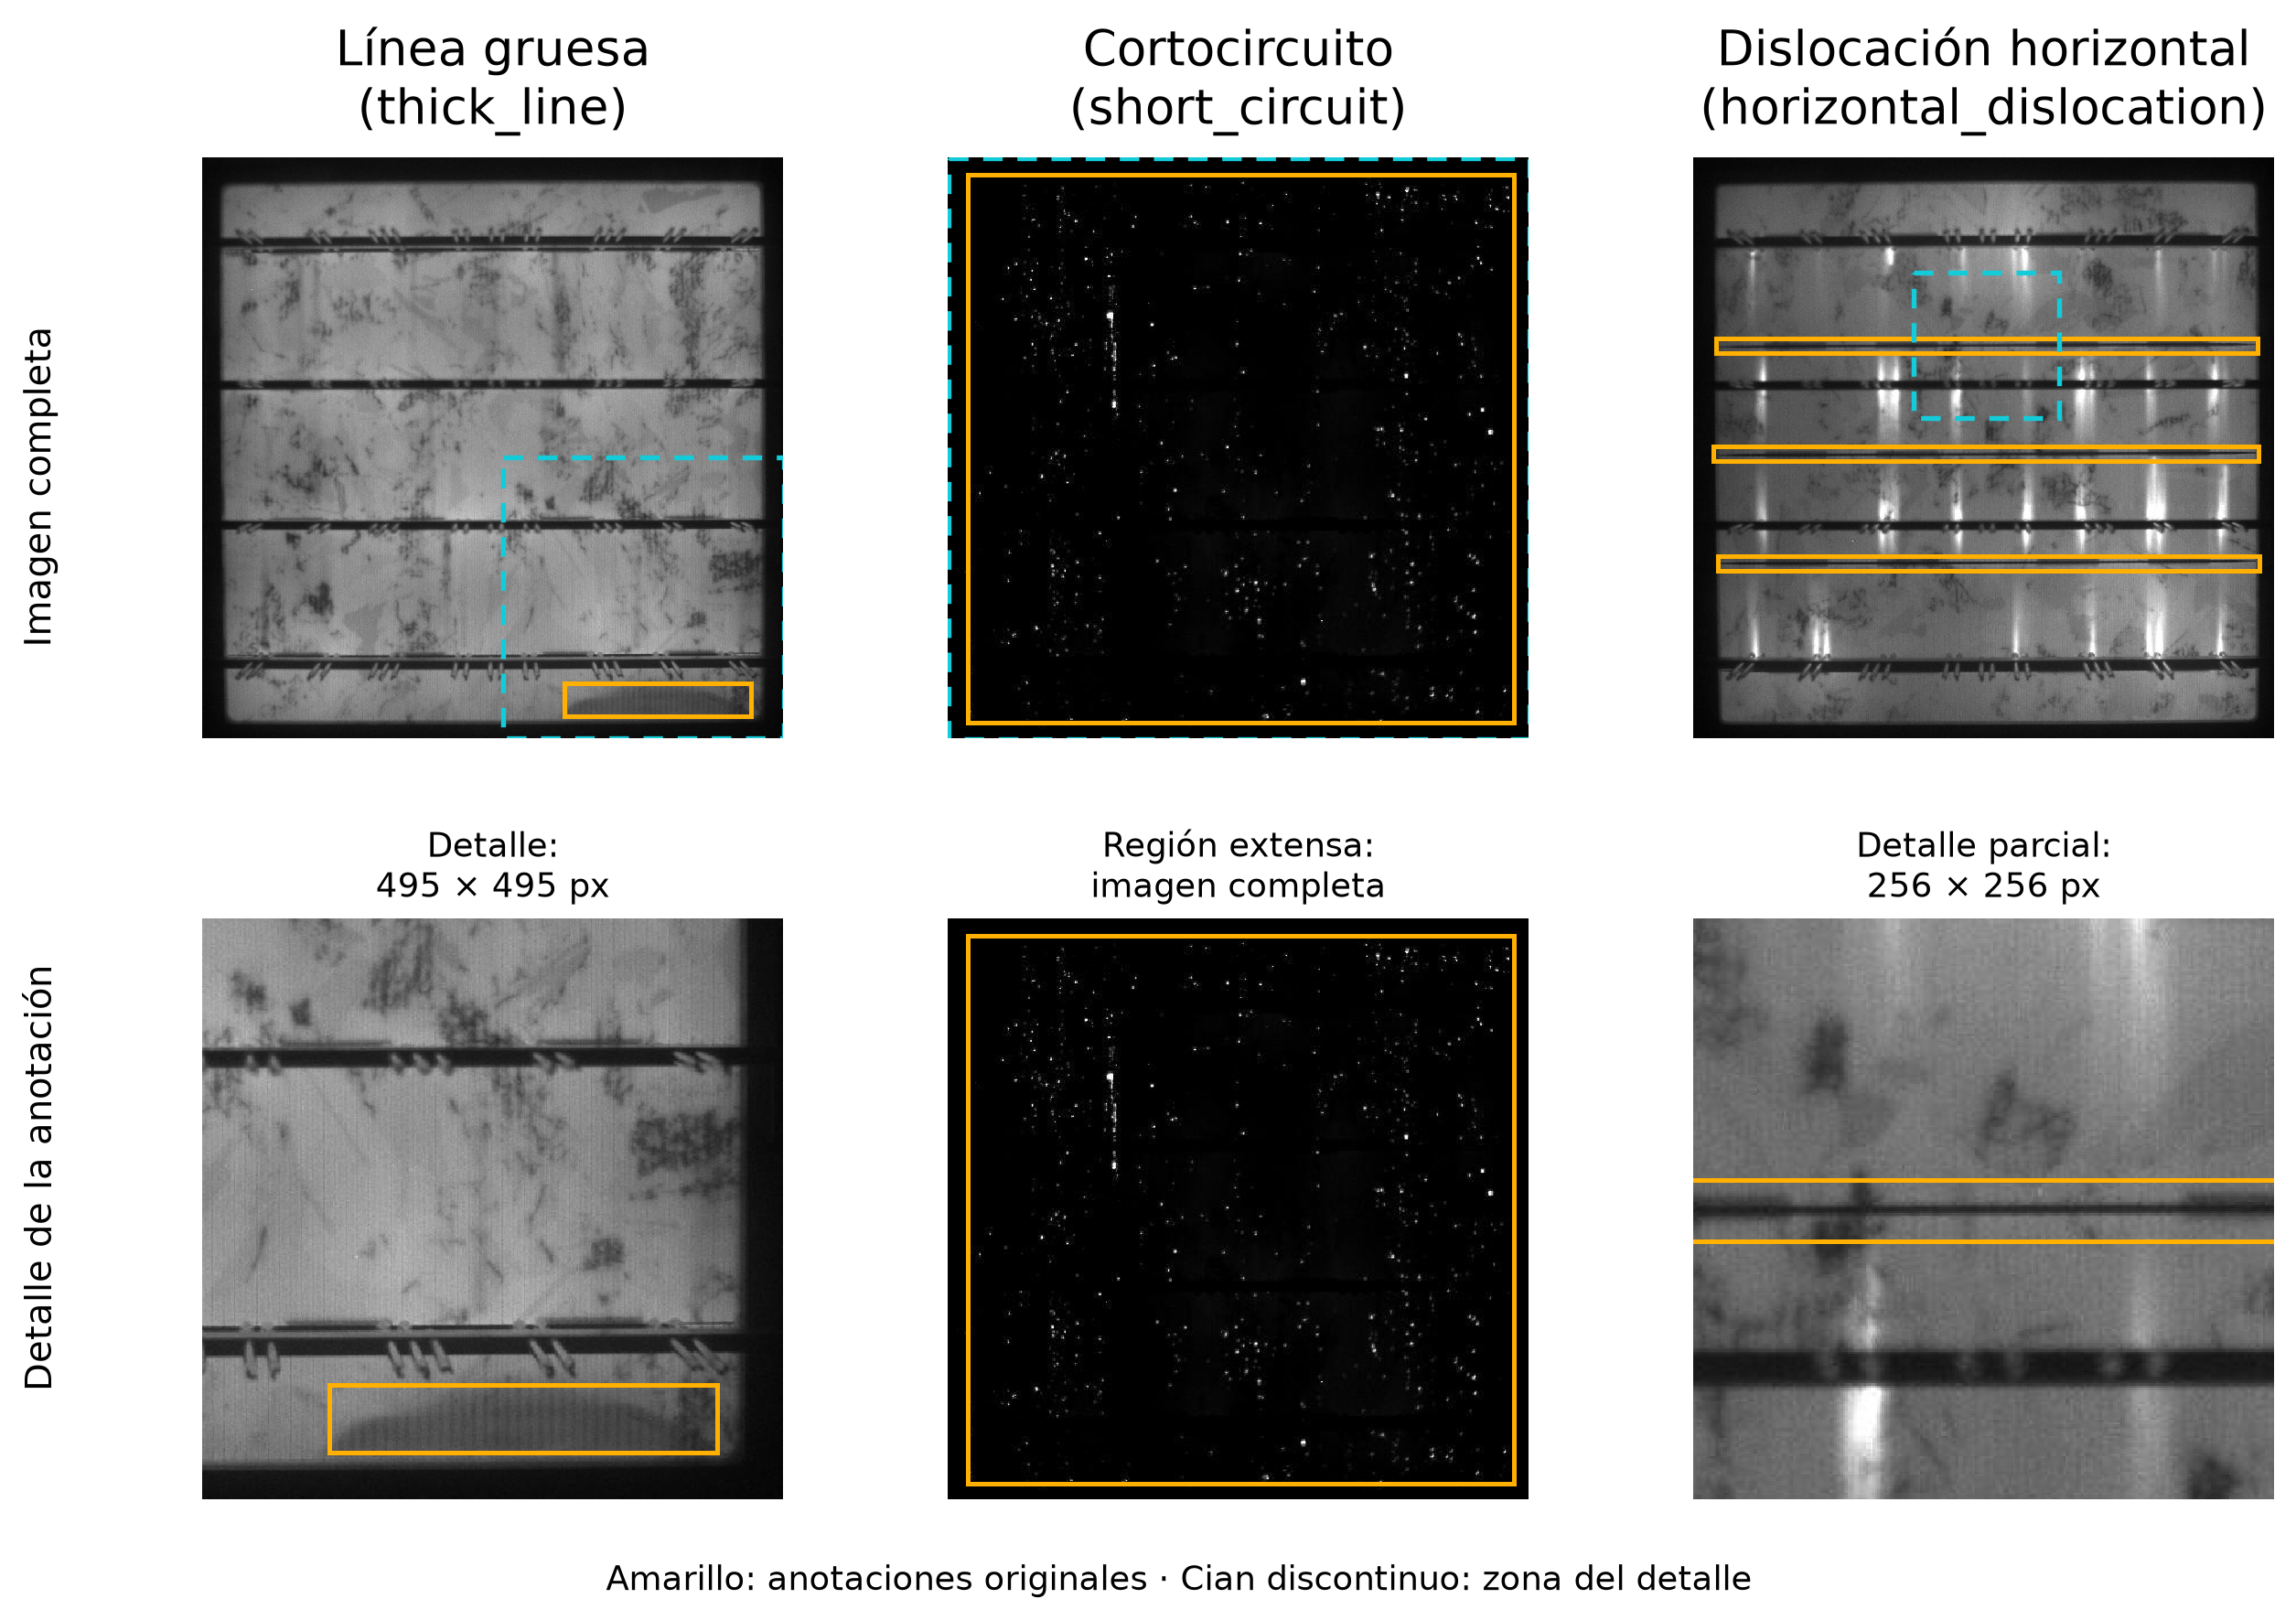

In [9]:
show_defect_examples(splits["train"], PROJECT_ROOT)